# 02 · The baseline sentiment model

**What this does.** Trains a simple, fast model that reads a review and says whether it is **positive, neutral or negative**, and measures how good it is on reviews it has never seen.

**Why start simple.** A baseline is a yardstick. The fine-tuned language model in notebook 03 costs GPU time, so it has to clearly beat this one **on the same test set** to be worth it. A simple model is also easy to explain: we can list exactly which words push a review towards each label.

**How it works, in two steps.**
1. **TF-IDF** turns each review into numbers: one per word or short phrase (up to three words, so *"not good"* counts as its own phrase). Words that are common in this review but rare overall get higher numbers.
2. **Logistic regression** learns a weight for every word and phrase per label, adds them up for a review, and picks the label with the highest total.

**Balanced class weights** make mistakes on rare labels (neutral) count for more, so the model can't ignore them.

In [1]:
import time

import joblib
import matplotlib.pyplot as plt
import pandas as pd

from review_intel import config
from review_intel.models.baseline import top_terms, train_baseline
from review_intel.models.metrics import evaluate, evaluate_by_domain, save_metrics

FIG = config.REPORTS_DIR / "figures"
pd.set_option("display.max_colwidth", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_parquet(config.INTERIM_DIR / "reviews.parquet")
train, val, test = (df[df["split"] == s].reset_index(drop=True) for s in ("train", "val", "test"))
print(f"train {len(train):,} · val {len(val):,} · test {len(test):,}")

train 119,976 · val 15,028 · test 14,996


## 1. Train

The model has one setting to choose, **C**: how much it is held back from memorising the training reviews. We try four values and keep the one that scores best on the **validation** set. The **test** set stays untouched until the very end, so the final score is honest.

In [2]:
start = time.time()
model = train_baseline(train, val, seed=config.SEED)
print(f"Trained in {time.time() - start:,.0f} s · chosen C = {model.chosen_C} · validation macro F1 = {model.val_macro_f1:.3f}")

Trained in 236 s · chosen C = 2 · validation macro F1 = 0.718


## 2. How good is it on unseen reviews?

**Macro F1** is the headline number. It's the average of the F1 score for each label, so the rare neutral label counts as much as positive.
- 1.0 is perfect.
- A model that always says "positive" scores about 0.29, even though its *accuracy* looks good (around 74%).

That "lazy" model is shown below for comparison.

In [3]:
test["pred"] = model.predict(test["text"])
m = evaluate(test["label"], test["pred"])
lazy = evaluate(test["label"], ["positive"] * len(test))
pd.DataFrame({
    "baseline (TF-IDF + LR)": {"macro F1": m["macro_f1"], "accuracy": m["accuracy"]},
    "always 'positive'": {"macro F1": lazy["macro_f1"], "accuracy": lazy["accuracy"]},
}).T.round(3)

,macro F1,accuracy
baseline (TF-IDF + LR),0.732,0.872
always 'positive',0.283,0.740


**Per label.**
- **Precision:** of the reviews the model called *X*, how many really were *X*.
- **Recall:** of the reviews that really were *X*, how many the model found.

In [4]:
pd.DataFrame(m["per_class"]).T.round(3)

,precision,recall,f1,support
negative,0.783,0.842,0.812,2751.0
neutral,0.391,0.516,0.445,1155.0
positive,0.967,0.916,0.941,11090.0


**Confusion matrix.** Rows are the true label and columns are what the model said. The diagonal is correct; everything else is a mistake. Each row is shown as percentages, so you can read off where each true label's reviews end up.

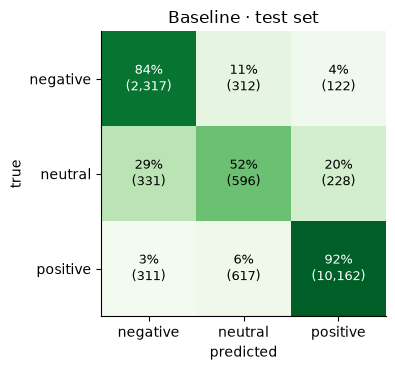

In [5]:
cm = pd.DataFrame(m["confusion"], index=config.LABELS, columns=config.LABELS)
pct = cm.div(cm.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(4.6, 3.8))
ax.imshow(pct, cmap="Greens", vmin=0, vmax=100)
ax.set_xticks(range(3), config.LABELS); ax.set_yticks(range(3), config.LABELS)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{pct.iloc[i, j]:.0f}%\n({cm.iloc[i, j]:,})", ha="center", va="center",
                color="white" if pct.iloc[i, j] > 60 else "black", fontsize=9)
ax.set_title("Baseline · test set")
plt.tight_layout(); plt.savefig(FIG / "02_baseline_confusion.png"); plt.show()

## 3. Does it work equally well for every kind of shop?

A combined score can hide a weak domain, so here is each domain on its own.

In [6]:
by_domain = evaluate_by_domain(test, "pred")
pd.DataFrame({d: {"macro F1": v["macro_f1"], "accuracy": v["accuracy"], "neutral F1": v["per_class"]["neutral"]["f1"]}
              for d, v in by_domain.items()}).T.round(3)

,macro F1,accuracy,neutral F1
appliances,0.688,0.894,0.301
grocery,0.722,0.874,0.424
restaurant,0.753,0.848,0.510


## 4. What has it learned?

These are the words and phrases with the biggest pull towards each label. It's a direct look inside the model, and a sanity check that it learned sensible things.

In [7]:
terms = top_terms(model, n=15)
pd.DataFrame({label: terms[label] for label in config.LABELS})

,negative,neutral,positive
0,not,but,great
1,terrible,ok,delicious
2,horrible,three stars,perfect
3,worst,however,amazing
4,not good,decent,best
5,awful,okay,awesome
6,disgusting,though,love
7,very disappointed,not,excellent
8,poor,alright,good
9,disappointment,average,perfectly


## 5. Where does it go wrong?

Here are a few wrong predictions, to see *why* it fails. Typical causes:
- **mixed reviews** ("great food, terrible service");
- **sarcasm**;
- **stars that disagree with the words**;
- **negation it can't see**.

The fine-tuned model in notebook 03 reads whole sentences, so it should do better on these.

In [8]:
wrong = test[test["label"] != test["pred"]].sample(8, random_state=config.SEED)
wrong.assign(text=wrong["text"].str.slice(0, 220))[["domain", "stars", "label", "pred", "text"]]

[Output removed before publishing: it shows review text, which the Yelp and Amazon licences don't allow us to republish. Run the notebook locally to see it.]


## 6. Save the model and its scores

The scores go to `pipeline/reports/metrics/baseline.json`, so notebook 03 can compare against exactly these numbers. The trained model goes to `pipeline/models/`, which stays local.

In [9]:
path = save_metrics("baseline", {**m, "by_domain": by_domain, "chosen_C": model.chosen_C,
                                   "val_macro_f1": model.val_macro_f1, "always_positive_macro_f1": lazy["macro_f1"]},
                    test_size=len(test))
config.MODELS_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(model, config.MODELS_DIR / "baseline.joblib")
print("saved", path.relative_to(config.REPO_ROOT), "and", (config.MODELS_DIR / "baseline.joblib").relative_to(config.REPO_ROOT))

saved pipeline\reports\metrics\baseline.json and pipeline\models\baseline.joblib


## Key findings

1. **The baseline reaches macro F1 0.732 on 14,996 unseen reviews** (87.2% accuracy). The lazy "always positive" model scores 0.283 (74.0% accuracy). This is the number DistilBERT has to beat in notebook 03.

2. **Positive and negative are easy; neutral is hard.**
   - F1 is 0.94 for positive and 0.81 for negative, but only **0.45 for neutral**.
   - Only 52% of truly neutral reviews are recognised. The rest are split between negative (29%) and positive (20%).
   - 3★ reviews mix praise and complaints ("decent food **but** …"), and a word-counting model can't weigh one against the other. Its top neutral words prove the point: *but, however, though, ok, decent*.

3. **Appliances are the weakest domain** (macro F1 0.69; neutral F1 only 0.30). Restaurants are the strongest (0.75). Appliance reviews are short, and 3★ appliance reviews often read like complaints (good value, but it didn't last).

4. **What it learned is sensible:** *terrible, horrible, worst, not good, rude, bland* for negative; *great, delicious, perfect, love* for positive.

5. **Negation is its blind spot.** *"not"* is its strongest negative word on its own, so "not bad" and "couldn't be happier" go wrong. The mistakes above show mixed reviews and negation as the main causes. A model that reads whole sentences should fix much of this.

6. **The first run leaked the label.** Amazon's automatic "Five Stars" titles made up about 8% of Amazon reviews, and that run scored 0.741. After removing them, the honest score is **0.732**. Small in total, but the model had been learning *"five stars" → positive* instead of reading the review.

7. **The setting chosen was C = 2,** inside the tried range (0.5–8), so the range was wide enough. Training took about 4 minutes on the laptop, for free.